<a href="https://colab.research.google.com/github/isaagianni/TP_Final_Vision/blob/main/02_exploracion_dataset_propio.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Exploración del dataset propio

Análisis exploratorio de fotografías reales de heladeras, utilizadas para complementar el entrenamiento de YOLO y DETR.

El dataset contiene fotografías de una heladera diferente de la utilizada en AI Cook, con variaciones de iluminación, perspectiva, disposición de alimentos y oclusiones.

In [1]:
from google.colab import files
uploaded = files.upload()

Saving heladera-train_.v1-heladera_train.yolov8.zip to heladera-train_.v1-heladera_train.yolov8.zip


In [2]:

from pathlib import Path
from zipfile import ZipFile

zip_name = next(iter(uploaded))

# Carpeta exclusiva para nuestras fotografías
dataset_dir = Path("/content/heladera_propia")
dataset_dir.mkdir(parents=True, exist_ok=True)

with ZipFile(zip_name, "r") as zip_file:
    zip_file.extractall(dataset_dir)

print("Dataset propio descomprimido correctamente")
print("\nContenido:")

for item in sorted(dataset_dir.iterdir()):
    print(item.name)


Dataset propio descomprimido correctamente

Contenido:
README.roboflow.txt
data.yaml
train


# Verificar imágenes y etiquetas

In [3]:

image_dir = dataset_dir / "train" / "images"
label_dir = dataset_dir / "train" / "labels"

image_files = sorted([
    p for p in image_dir.iterdir()
    if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
])

label_files = sorted(label_dir.glob("*.txt"))

print("Fotografías:", len(image_files))
print("Archivos de etiquetas:", len(label_files))

# Verificar que cada fotografía tenga su archivo de etiquetas
image_names = {p.stem for p in image_files}
label_names = {p.stem for p in label_files}

print("Fotografías sin etiquetas:", len(image_names - label_names))
print("Etiquetas sin fotografía:", len(label_names - image_names))

# Contar bounding boxes
total_boxes = sum(
    len(p.read_text().splitlines())
    for p in label_files
)

print("Total de bounding boxes:", total_boxes)


Fotografías: 79
Archivos de etiquetas: 79
Fotografías sin etiquetas: 0
Etiquetas sin fotografía: 0
Total de bounding boxes: 1397


# distribución de clases

Cantidad de clases: 12
Clases: ['apple', 'banana', 'bread', 'butter', 'cheese', 'eggs', 'ham', 'heavy_cream', 'onion', 'potato', 'strawberries', 'tomato']


,Clase,Bounding boxes
11,tomato,207
5,eggs,201
9,potato,139
1,banana,138
0,apple,110
6,ham,108
2,bread,104
10,strawberries,83
4,cheese,81
8,onion,79


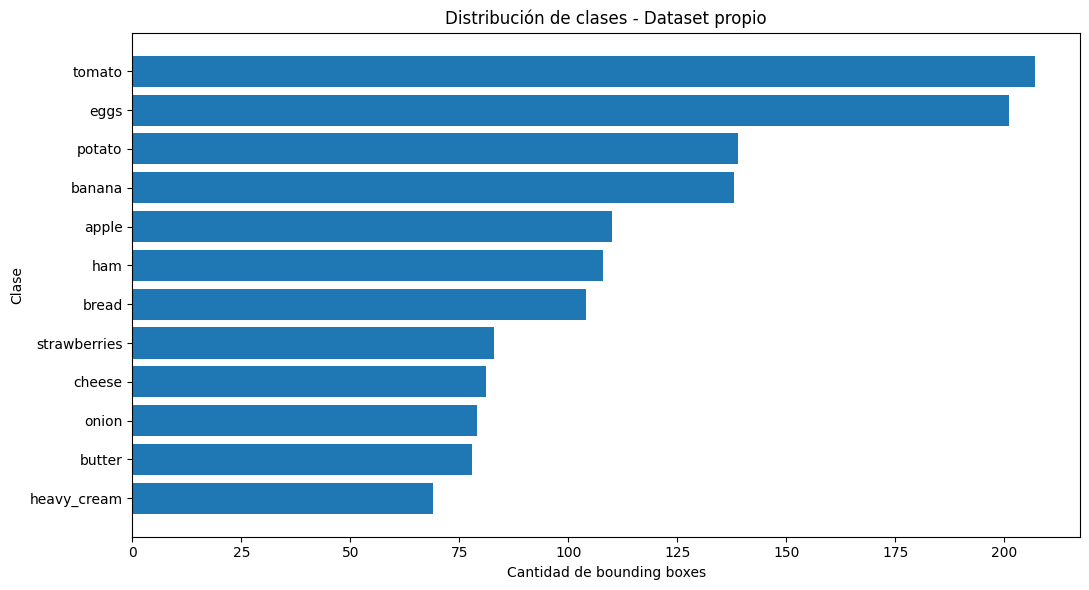

In [4]:

import yaml
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

# Leer las clases definidas por Roboflow
with open(dataset_dir / "data.yaml", "r") as file:
    data = yaml.safe_load(file)

class_names = data["names"]

# Convertir a una lista ordenada por ID
if isinstance(class_names, dict):
    class_names = [
        class_names[i] for i in sorted(class_names)
    ]

print("Cantidad de clases:", len(class_names))
print("Clases:", class_names)

# Contar apariciones de cada clase
class_counts = Counter()

for label_path in label_files:
    for line in label_path.read_text().splitlines():
        class_id = int(line.split()[0])
        class_counts[class_names[class_id]] += 1

# Crear tabla
df_classes = pd.DataFrame({
    "Clase": class_names,
    "Bounding boxes": [
        class_counts.get(name, 0)
        for name in class_names
    ]
})

df_classes = df_classes.sort_values(
    "Bounding boxes", ascending=False
)

display(df_classes)

# Graficar distribución
plt.figure(figsize=(11, 6))

plt.barh(
    df_classes["Clase"],
    df_classes["Bounding boxes"]
)

plt.xlabel("Cantidad de bounding boxes")
plt.ylabel("Clase")
plt.title("Distribución de clases - Dataset propio")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


# cantidad de objetos por fotografía

count    79.000000
mean     17.683544
std       2.696362
min      13.000000
25%      16.000000
50%      17.000000
75%      19.000000
max      27.000000
Name: Cantidad de objetos, dtype: float64


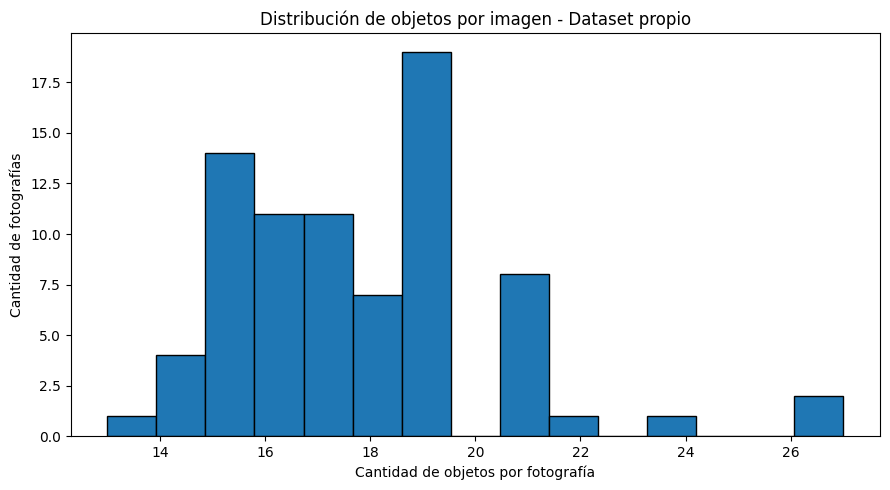

In [5]:

# Cantidad de objetos por fotografía
objects_per_image = []

for image_path in image_files:
    label_path = label_dir / f"{image_path.stem}.txt"

    lines = label_path.read_text().splitlines()
    objects_per_image.append(len(lines))

# Resumen estadístico
df_objects = pd.DataFrame({
    "Imagen": [p.name for p in image_files],
    "Cantidad de objetos": objects_per_image
})

print(df_objects["Cantidad de objetos"].describe())

# Histograma
plt.figure(figsize=(9, 5))

plt.hist(
    objects_per_image,
    bins=15,
    edgecolor="black"
)

plt.xlabel("Cantidad de objetos por fotografía")
plt.ylabel("Cantidad de fotografías")
plt.title("Distribución de objetos por imagen - Dataset propio")
plt.tight_layout()
plt.show()


# Distribución de tamaños de bounding boxes

Estadísticas del tamaño de los bounding boxes:
count    1397.000000
mean        0.966557
std         0.913344
min         0.050735
25%         0.414340
50%         0.707944
75%         1.184082
max         7.671738
Name: Área (%), dtype: float64

Porcentaje de boxes con área menor al 1%:
65.71%

Porcentaje de boxes con área menor al 2%:
91.20%


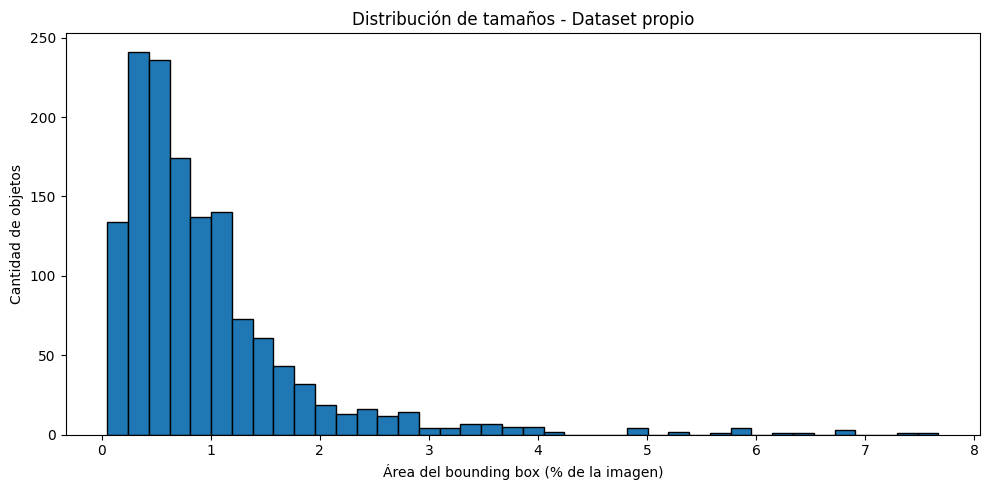

In [6]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

box_areas = []
box_classes = []

for label_path in label_files:
    with open(label_path, "r") as file:
        for line in file:
            values = line.strip().split()

            if len(values) != 5:
                continue

            class_id = int(values[0])
            x, y, w, h = map(float, values[1:])

            # Porcentaje de la imagen ocupado por el box
            area_pct = w * h * 100

            box_areas.append(area_pct)
            box_classes.append(class_names[class_id])

df_boxes = pd.DataFrame({
    "Clase": box_classes,
    "Área (%)": box_areas
})

print("Estadísticas del tamaño de los bounding boxes:")
print(df_boxes["Área (%)"].describe())

print("\nPorcentaje de boxes con área menor al 1%:")
print(f"{(df_boxes['Área (%)'] < 1).mean() * 100:.2f}%")

print("\nPorcentaje de boxes con área menor al 2%:")
print(f"{(df_boxes['Área (%)'] < 2).mean() * 100:.2f}%")

# Histograma
plt.figure(figsize=(10, 5))

plt.hist(
    df_boxes["Área (%)"],
    bins=40,
    edgecolor="black"
)

plt.xlabel("Área del bounding box (% de la imagen)")
plt.ylabel("Cantidad de objetos")
plt.title("Distribución de tamaños - Dataset propio")

plt.tight_layout()
plt.show()


,Cantidad,Media (%),Mediana (%),Mínimo (%),Máximo (%)
Clase,,,,,
eggs,201,0.885,0.295,0.056,7.672
tomato,207,0.487,0.463,0.051,1.477
apple,110,0.610,0.525,0.195,1.465
onion,79,0.677,0.614,0.138,1.800
potato,139,0.760,0.696,0.067,1.813
butter,78,0.793,0.717,0.299,2.547
ham,108,1.079,0.966,0.185,4.880
bread,104,1.142,1.075,0.125,2.769
heavy_cream,69,1.020,1.077,0.145,1.942


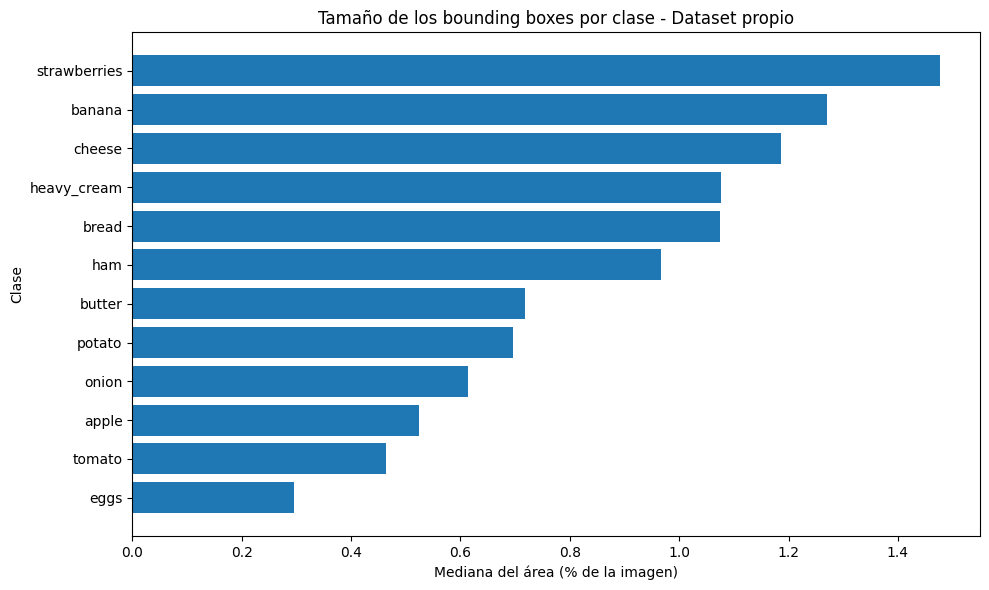

In [7]:

# Calcular estadísticas de tamaño por clase
df_sizes_by_class = (
    df_boxes.groupby("Clase")["Área (%)"]
    .agg(["count", "mean", "median", "min", "max"])
    .sort_values("median")
)

df_sizes_by_class.columns = [
    "Cantidad",
    "Media (%)",
    "Mediana (%)",
    "Mínimo (%)",
    "Máximo (%)"
]

display(df_sizes_by_class.round(3))

# Graficar la mediana del área por clase
plt.figure(figsize=(10, 6))

plt.barh(
    df_sizes_by_class.index,
    df_sizes_by_class["Mediana (%)"]
)

plt.xlabel("Mediana del área (% de la imagen)")
plt.ylabel("Clase")
plt.title("Tamaño de los bounding boxes por clase - Dataset propio")

plt.tight_layout()
plt.show()


# Visualizar anotaciones

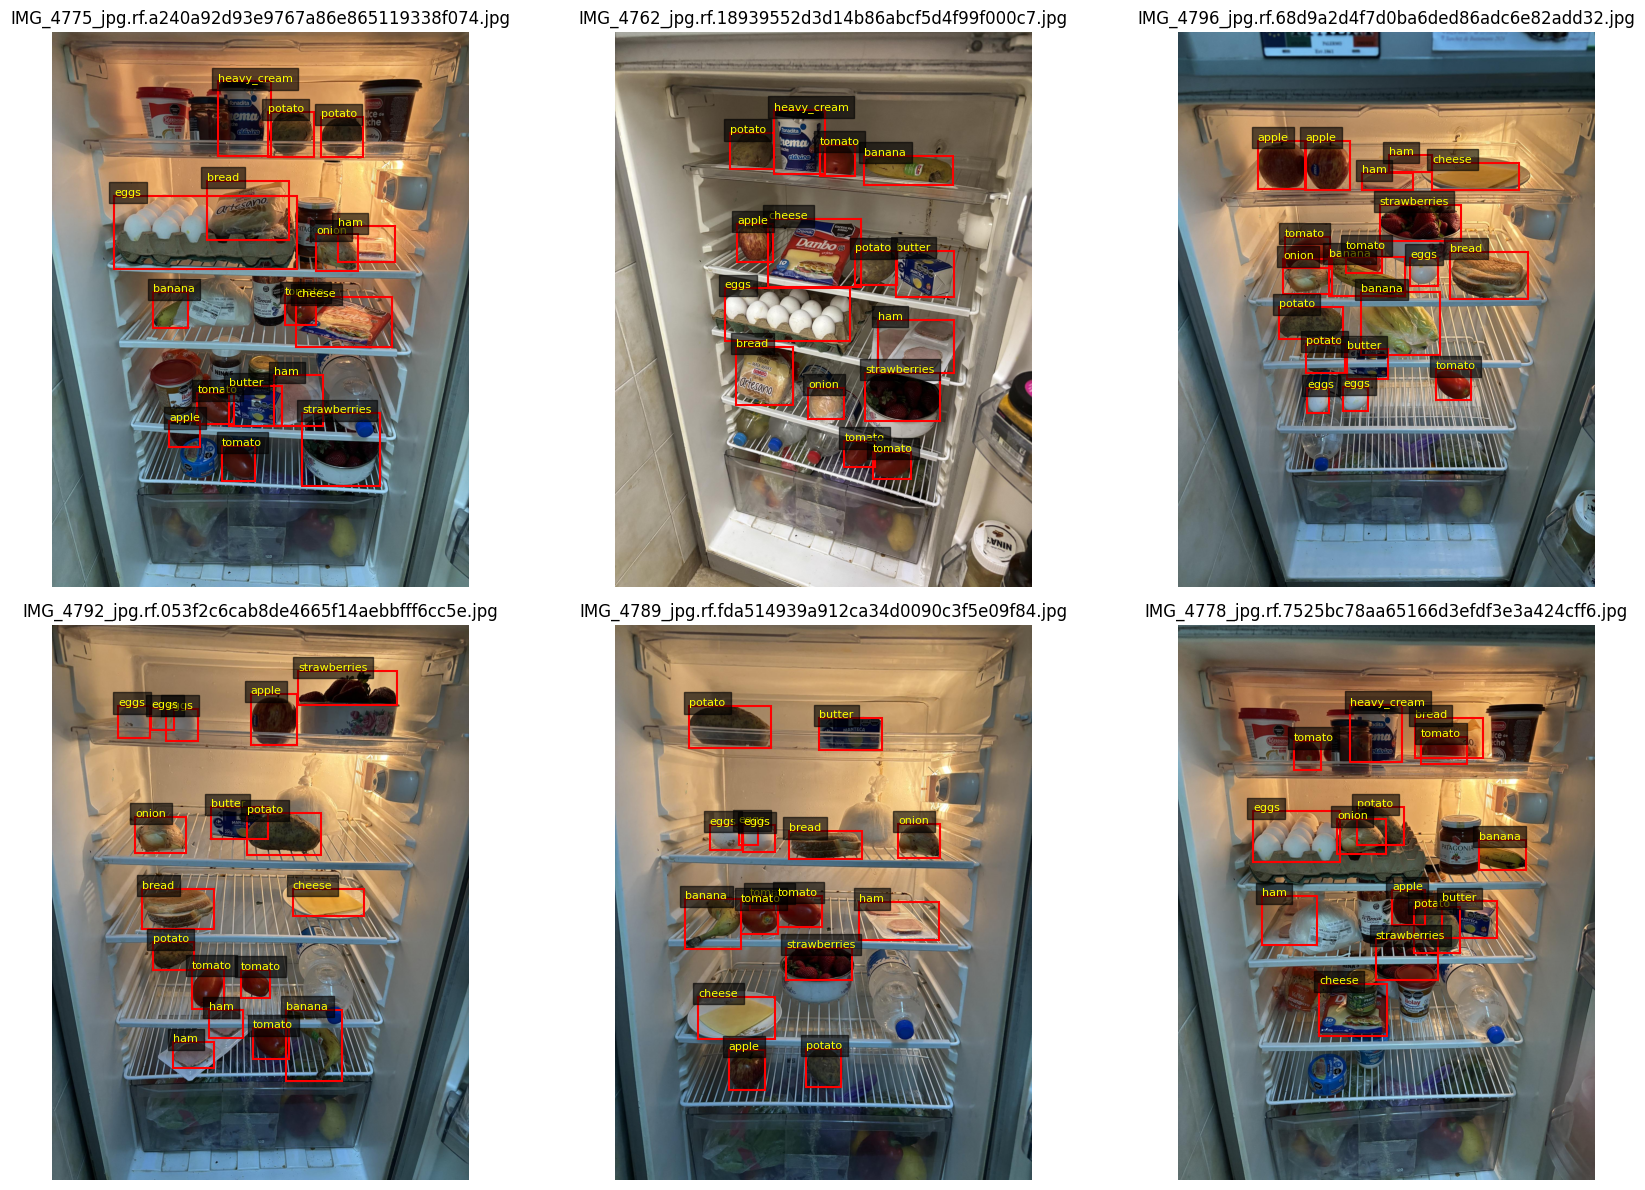

In [8]:

import random
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.patches as patches

# Seleccionar 6 fotografías aleatorias
random.seed(42)
selected_images = random.sample(image_files, 6)

fig, axes = plt.subplots(2, 3, figsize=(18, 12))

for ax, image_path in zip(axes.flat, selected_images):

    image = Image.open(image_path).convert("RGB")
    width, height = image.size

    ax.imshow(image)

    label_path = label_dir / f"{image_path.stem}.txt"

    with open(label_path, "r") as file:
        for line in file:

            class_id, x, y, w, h = map(
                float, line.strip().split()
            )

            class_id = int(class_id)

            # Convertir coordenadas YOLO a píxeles
            x_min = (x - w / 2) * width
            y_min = (y - h / 2) * height
            box_width = w * width
            box_height = h * height

            rect = patches.Rectangle(
                (x_min, y_min),
                box_width,
                box_height,
                linewidth=1.5,
                edgecolor="red",
                facecolor="none"
            )

            ax.add_patch(rect)

            ax.text(
                x_min,
                y_min,
                class_names[class_id],
                color="yellow",
                fontsize=8,
                bbox=dict(facecolor="black", alpha=0.6)
            )

    ax.set_title(image_path.name)
    ax.axis("off")

plt.tight_layout()
plt.show()


# Similitud entre imágenes propias

In [9]:

%pip -q install ImageHash

import imagehash
from PIL import Image
from itertools import combinations

# Calcular pHash de cada fotografía
hashes = {}

for image_path in image_files:
    with Image.open(image_path) as image:
        hashes[image_path.name] = imagehash.phash(image)

# Comparar todos los pares
similarities = []

for name1, name2 in combinations(hashes.keys(), 2):
    distance = hashes[name1] - hashes[name2]

    similarities.append({
        "Imagen 1": name1,
        "Imagen 2": name2,
        "Distancia pHash": distance
    })

df_similarity = pd.DataFrame(similarities)

print("Total de pares comparados:", len(df_similarity))

print("\nPares con pHash = 0:")
print((df_similarity["Distancia pHash"] == 0).sum())

print("\nPares con pHash <= 4:")
print((df_similarity["Distancia pHash"] <= 4).sum())

print("\nPares con pHash <= 8:")
print((df_similarity["Distancia pHash"] <= 8).sum())

print("\nLos 10 pares más similares:")

display(
    df_similarity.sort_values("Distancia pHash").head(10)
)


Total de pares comparados: 3081

Pares con pHash = 0:
0

Pares con pHash <= 4:
1

Pares con pHash <= 8:
4

Los 10 pares más similares:


,Imagen 1,Imagen 2,Distancia pHash
2451,IMG_4804_jpg.rf.f527deeb3e1d10b8288a69104ca869...,IMG_4805_jpg.rf.5a9f30a71a9bccd27a9b79d25f8ef8...,2
2220,IMG_4798_jpg.rf.055d09f08e277950a0ddb15e79c63e...,IMG_4799_jpg.rf.5d8be99947db0829702b1a90ec1e0d...,6
2093,IMG_4795_jpg.rf.185a33e9f7863c9ea284ea77d21b44...,IMG_4798_jpg.rf.055d09f08e277950a0ddb15e79c63e...,8
2094,IMG_4795_jpg.rf.185a33e9f7863c9ea284ea77d21b44...,IMG_4799_jpg.rf.5d8be99947db0829702b1a90ec1e0d...,8
157,IMG_4761_jpg.rf.d60dcaac49226f414c2a8abf76f479...,IMG_4764_jpg.rf.9f356d1fd5b84e4792a9d5be9abdd2...,10
871,IMG_4773_jpg.rf.a72a7bc4a70d8c3f85e358c2679bc4...,IMG_4775_jpg.rf.a240a92d93e9767a86e865119338f0...,10
1311,IMG_4780_jpg.rf.39a8e4eedc0cb73fdbd6ca997aacb4...,IMG_4781_jpg.rf.b18c010188e1ac9b7e9afcd64fa852...,10
2486,IMG_4805_jpg.rf.5a9f30a71a9bccd27a9b79d25f8ef8...,IMG_4806_jpg.rf.7d8a5b5af41a8c51204320b2afbe55...,10
2452,IMG_4804_jpg.rf.f527deeb3e1d10b8288a69104ca869...,IMG_4806_jpg.rf.7d8a5b5af41a8c51204320b2afbe55...,10
1252,IMG_4779_jpg.rf.dd5ddaafbb41dd37fc64cb9595cfc8...,IMG_4781_jpg.rf.b18c010188e1ac9b7e9afcd64fa852...,10


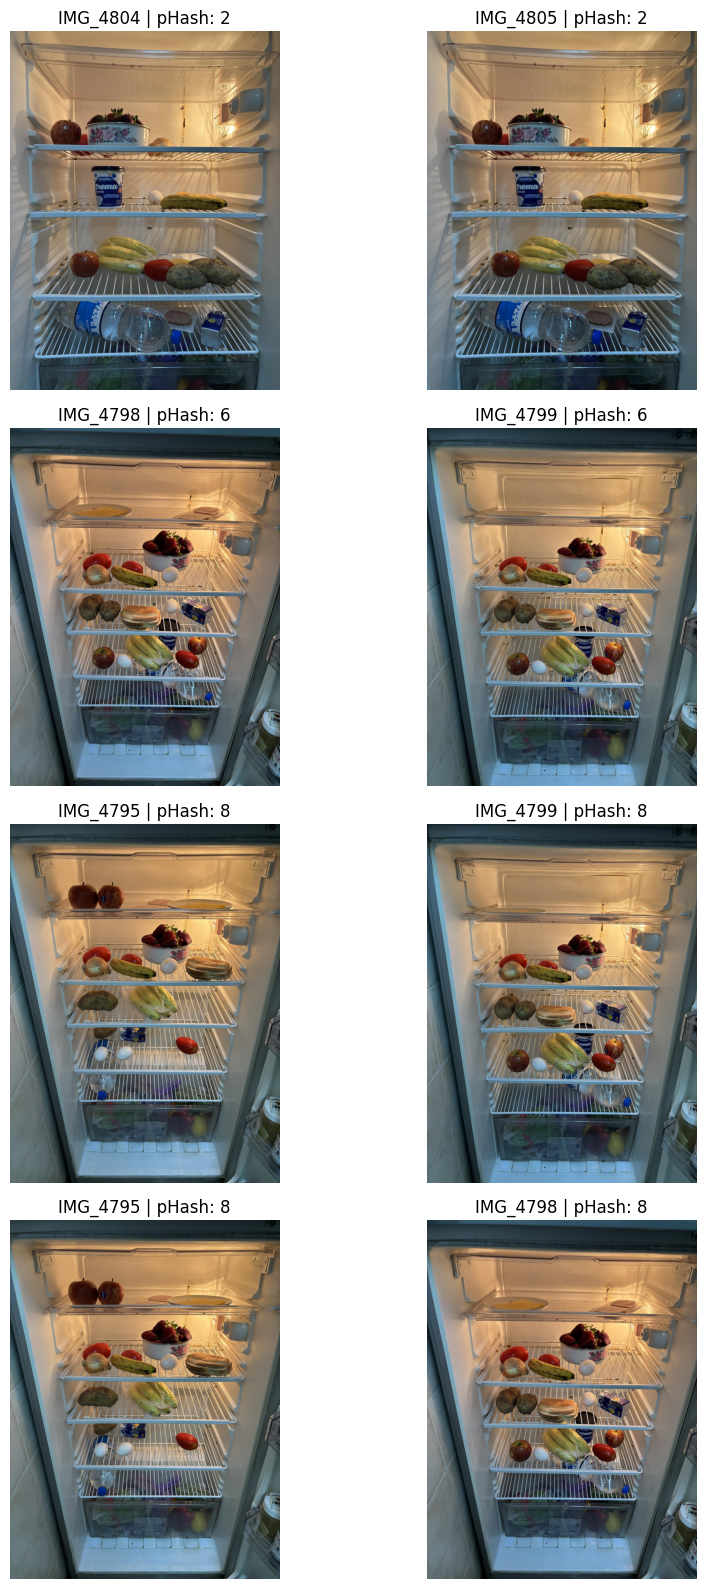

In [10]:

# Seleccionar pares con distancia pHash <= 8
similar_pairs = df_similarity[
    df_similarity["Distancia pHash"] <= 8
].sort_values("Distancia pHash")

# Relacionar nombres de imágenes con sus rutas
image_paths = {p.name: p for p in image_files}

fig, axes = plt.subplots(
    len(similar_pairs), 2,
    figsize=(10, 4 * len(similar_pairs)),
    squeeze=False
)

for i, (_, pair) in enumerate(similar_pairs.iterrows()):

    for j, column in enumerate(["Imagen 1", "Imagen 2"]):
        image_name = pair[column]
        image = Image.open(image_paths[image_name])

        axes[i, j].imshow(image)
        axes[i, j].set_title(
            f"{image_name.split('_jpg')[0]} "
            f"| pHash: {pair['Distancia pHash']}"
        )
        axes[i, j].axis("off")

plt.tight_layout()
plt.show()


# Validar las anotaciones

In [11]:

import math

errors = []
valid_boxes = 0
empty_files = 0

for label_path in label_files:

    lines = label_path.read_text().splitlines()

    if not lines:
        empty_files += 1

    for line_number, line in enumerate(lines, start=1):

        values = line.split()

        if len(values) != 5:
            errors.append(
                (label_path.name, line_number, "Formato incorrecto")
            )
            continue

        try:
            numbers = list(map(float, values))
            class_value, x, y, w, h = numbers

            valid = (
                all(math.isfinite(value) for value in numbers)
                and class_value.is_integer()
                and 0 <= class_value < len(class_names)
                and 0 < w <= 1
                and 0 < h <= 1
                and w / 2 <= x <= 1 - w / 2
                and h / 2 <= y <= 1 - h / 2
            )

            if valid:
                valid_boxes += 1
            else:
                errors.append(
                    (label_path.name, line_number, "Valores inválidos")
                )

        except ValueError:
            errors.append(
                (label_path.name, line_number, "Valor no numérico")
            )

print("Bounding boxes válidos:", valid_boxes)
print("Archivos de etiquetas vacíos:", empty_files)
print("Total de errores:", len(errors))
print("Primeros errores:", errors[:10])


Bounding boxes válidos: 1397
Archivos de etiquetas vacíos: 0
Total de errores: 0
Primeros errores: []
